# Coupled Lindblad dynamics and grouped energy readout

The bounded density study uses two systems with $H=0.6Z_0Z_1+0.35(X_0+X_1)$, local damping rates $(0.8,0.5)$, $t=1$ and $\hbar=1$. The default input is $|+i\rangle$ on system0 and $|+\rangle$ on system1. A Bell input is also gate-prepared and checked. Each environment is reset before every local dilation; no outcomes are postselected.

The global positive-time palindrome includes all Hamiltonian components and local dissipators. Exact component gates do not make the combined dynamics exact: its splitting error is compared with an independently assembled, time-scaled $16\times16$ Liouvillian exponential. A separate n-chain generator is executed for circuit counts; the full combined-generator accuracy study remains n=2.

Original MIT source/figures use Qiskit 2.6.2 (Apache-2.0), NumPy and SciPy 1.18.1 (BSD-3-Clause). No formal/Lean certificate or physical estimate is integrated.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

root = Path.cwd()
if not (root / "src/openquantum/simulation/two_spin_lindblad.py").exists() and (root.parent / "src/openquantum/simulation/two_spin_lindblad.py").exists():
    root = root.parent
if (root / "src/openquantum/simulation/two_spin_lindblad.py").exists():
    sys.path.insert(0, str(root / "src"))
    from openquantum.simulation import two_spin_lindblad as ts
else:
    # Save downloaded two_spin_lindblad.py and open_systems.py beside this notebook.
    sys.path.insert(0, str(root))
    import two_spin_lindblad as ts

time, J, hx, rates = 1.0, 0.6, 0.35, (0.8, 0.5)
reference = ts.exact_density(ts.initial_density("product"), time, J, hx, rates)
print(ts.expectation_values(reference, J, hx))

{'X0': -0.0675282893983524, 'X1': 0.4172064689004572, 'Y0': 0.0390866772045334, 'Y1': 0.2730141113519137, 'Z0': 0.7911337403681944, 'Z1': 0.46963209037117626, 'ZZ': 0.46174839654907074, 'energy': 0.39943640075517906}


## Global second-order step

Chronological order: ZZ(dt/2), Xlayer(dt/2), D0(dt/2), D1(dt), D0(dt/2), Xlayer(dt/2), ZZ(dt/2). Every component receives total dt. A half damping step uses $1-e^{-\gamma_i dt/2}$. There is no separately approximated combined-H substep: the global error includes Hamiltonian-term and Hamiltonian/damping commutators.

System wires0/1 have environment wires2/3. D0 is called twice and D1 once per symmetric step, with resets before every call. The diagram shows one step plus final Z readout.

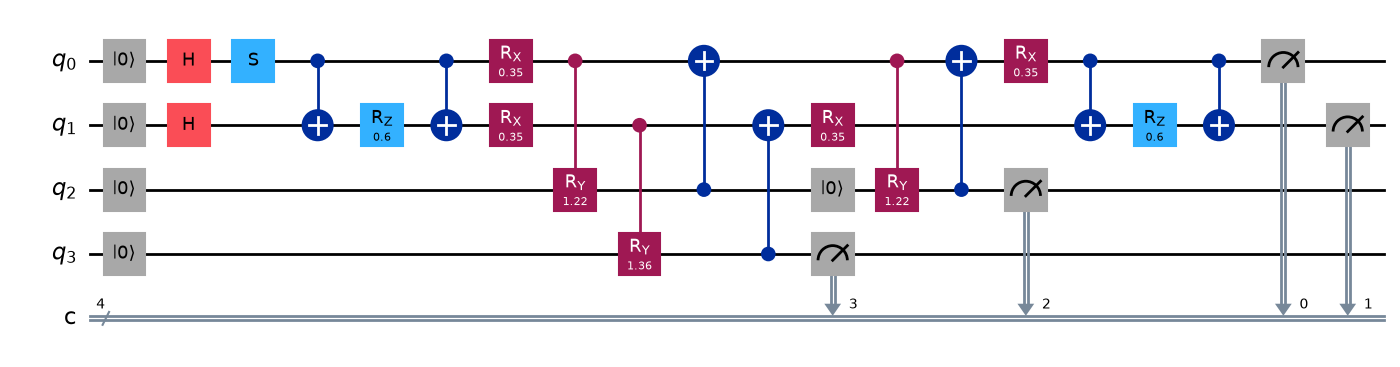

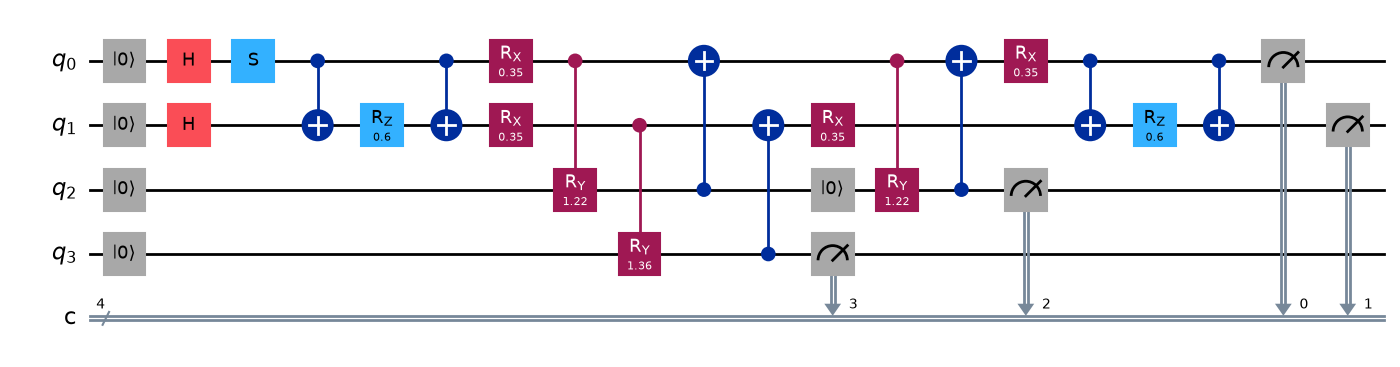

In [2]:
ts.build_two_spin_circuit(time, J, hx, rates, steps=1, order=2, observable="Z").draw(output="mpl", fold=30)

## Actual reduced state versus independent references

Qiskit DensityMatrix evaluates the gate/reset circuit, then traces both environments. The reference uses standard GKSL column vectorization and a $16\times16$ exponential built from scaled coefficients. Another classical split-component matrix check validates the stated schedule. Neither matrix is a quantum operation.

In [3]:
records = [ts.compare_two_spin(time, J, hx, rates, steps=r, order=o) for o in (1, 2) for r in (1, 2, 4, 8, 16, 32)]
rows = [{"order": r["order"], "steps": r["steps"], "trace distance": r["trace_distance"],
         "ZZ bias": r["observable_errors"]["ZZ"], "energy bias": r["observable_errors"]["energy"],
         "H-only diagnostic": r["hamiltonian_only_trace_distance_diagnostic"]} for r in records]
display(pd.DataFrame(rows).query("steps in [8, 16, 32]").reset_index(drop=True))
assert max(r["circuit_vs_classical_split_trace_distance"] for r in records) < 2e-11
assert min(r["minimum_eigenvalue"] for r in records) > -2e-11
selected = ts.compare_two_spin(time, J, hx, rates, steps=32, order=2)

,order,steps,trace distance,ZZ bias,energy bias,H-only diagnostic
0,1,8,0.021286,0.002979,0.000205,0.029698
1,1,16,0.010679,0.002006,0.000320,0.014884
2,1,32,0.005352,0.001133,0.000214,0.007452
3,2,8,0.001339,0.000901,0.000436,0.001031
4,2,16,0.000334,0.000224,0.000109,0.000258
5,2,32,0.000084,0.000056,0.000027,0.000064


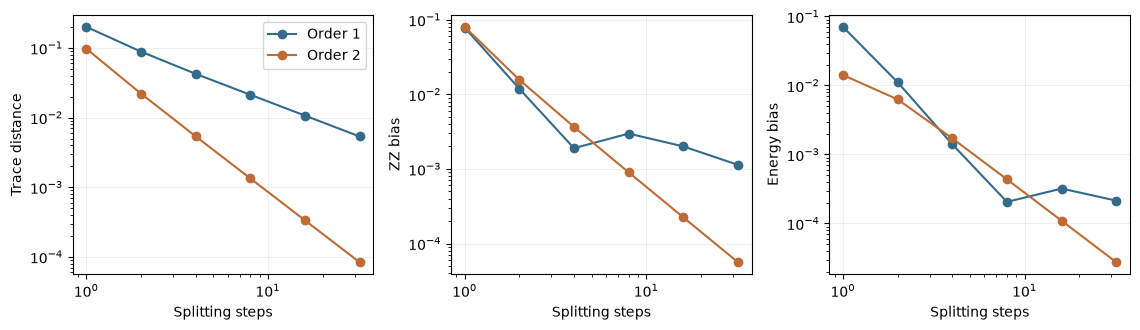

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.4))
for order, color in ((1, "#346b8a"), (2, "#be6b35")):
    group = [r for r in records if r["order"] == order]
    for ax, key, ylabel in zip(axes, ("trace_distance", "ZZ", "energy"), ("Trace distance", "ZZ bias", "Energy bias")):
        values = [r[key] if key == "trace_distance" else r["observable_errors"][key] for r in group]
        ax.loglog([r["steps"] for r in group], values, "o-", label=f"Order {order}", color=color)
        ax.set(xlabel="Splitting steps", ylabel=ylabel)
        ax.grid(alpha=.2)
axes[0].legend()
fig.tight_layout()
plt.show()

In [5]:
actual = ts.simulate_two_spin(time, J, hx, rates, steps=32, order=2)
display(pd.DataFrame(actual, index=["00", "01", "10", "11"], columns=["00", "01", "10", "11"]))
display(pd.DataFrame({"actual": selected["circuit_observables"], "exact": selected["exact_observables"], "bias": selected["observable_errors"]}))
print(f"Trace {np.trace(actual).real:.12f}; minimum eigenvalue {np.linalg.eigvalsh(actual).min():.12f}")

,00,01,10,11
00,0.680601-0.000000j,-0.107504+0.000773j,0.223674-0.174118j,0.054045-0.120194j
01,-0.107504-0.000773j,0.054174+0.000000j,-0.054045+0.034138j,-0.015015+0.037618j
10,0.223674+0.174118j,-0.054045-0.034138j,0.214980+0.000000j,0.073771-0.020349j
11,0.054045+0.120194j,-0.015015-0.037618j,0.073771+0.020349j,0.050245-0.000000j


,actual,exact,bias
X0,-0.067467,-0.067528,0.000061
X1,0.417319,0.417206,0.000113
Y0,0.039151,0.039087,0.000064
Y1,0.273000,0.273014,0.000014
Z0,0.791163,0.791134,0.000029
Z1,0.469550,0.469632,0.000082
ZZ,0.461692,0.461748,0.000056
energy,0.399464,0.399436,0.000027


Trace 1.000000000000; minimum eigenvalue 0.005646675681


The H-only diagnostic repeats the same global formula with damping disabled. It shows Hamiltonian-term splitting error, and is not added to the full global error: that error already contains all commutators. The reported state errors are numerical, not diamond-norm or interval certificates.

## Full measured trials and energy groups

X/Y/Z readout rotates every system into its requested basis, measures all four wires and ignores both environment bits. The energy uses an X-group score $0.35(x_0+x_1)$ and a Z-group score $0.6z_0z_1$. The two bits within a group may be correlated. One trial supplies one bounded scalar score; independent trials, not independent qubits, enter Hoeffding.

In [6]:
counts = {}
for group in ("X", "Y", "Z"):
    trial = ts.lower_to_rotation_basis(ts.build_two_spin_circuit(time, J, hx, rates, steps=32, order=2, observable=group))
    counts[group] = dict(trial.count_ops())
display(pd.DataFrame(counts).fillna(0).astype(int))
budget = ts.energy_shot_budget(J, hx)
display(pd.DataFrame(budget["groups"]).T)
print("Total proposed X+Z trials:", budget["total_trials"])
energy = 0.0
for group in ("X", "Z"):
    trial = ts.lower_to_rotation_basis(ts.build_two_spin_circuit(time, J, hx, rates, steps=32, order=2, observable=group))
    energy += ts.measured_system_probabilities(trial) @ ts.group_scores(group, J, hx)
assert abs(energy-selected["circuit_observables"]["energy"]) < 2e-11

,X,Y,Z
cx,354,354,354
ry,192,192,192
rx,128,128,128
reset,98,98,98
rz,33,33,33
h,4,4,2
measure,4,4,4
s,1,1,1
sdg,0,2,0


,outcome_min,outcome_max,width,statistical_error,statistical_failure,trials
X,-0.7,0.7,1.4,0.015,0.0025,29116.0
Z,-0.6,0.6,1.2,0.015,0.0025,21391.0


Total proposed X+Z trials: 50507


The 29,116 X and 21,391 Z trials allocate sampling error 0.015 and failure 0.0025 to each group. A union bound gives total sampling error 0.03 and failure 0.005 for one fixed energy mean. Other observables/settings need separate confidence allocations. Splitting bias, coherent synthesis and physical faults are separately proposed; continuous rotations remain unsynthesized.

## Executed circuit scaling and bounded density scope

The generator supports n up to16 with an open ZZ chain, an X layer and local damping. It prepares $|+i\rangle$ on system0 and $|+\rangle$ elsewhere. Its space is 2n logical wires. Counts below are actual circuit construction/decomposition at fixed r, not an equal-accuracy n comparison. Full GKSL error curves here are n=2; tests include one n=3 split-component functional check. Larger-n density accuracy and formal bounds remain unvalidated.

In [7]:
scaling = []
for n_system in (1, 2, 3, 4, 8):
    trial = ts.build_chain_circuit(n_system, steps=4, order=2, observable="Z")
    compiled = ts.lower_to_rotation_basis(trial)
    scaling.append({"systems": n_system, "environments": n_system, "steps": 4,
                    "logical qubits": compiled.num_qubits, "primitive operations": compiled.size(),
                    "CX": compiled.count_ops().get("cx", 0), "reset": compiled.count_ops().get("reset", 0),
                    "measure": compiled.count_ops().get("measure", 0)})
display(pd.DataFrame(scaling))

,systems,environments,steps,logical qubits,primitive operations,CX,reset,measure
0,1,1,4,2,33,12,5,2
1,2,2,4,4,112,46,14,4
2,3,3,4,6,205,92,23,6
3,4,4,4,8,289,132,32,8
4,8,8,4,16,625,292,68,16


## Scope and exclusions

Generation is capped at16 systems, 1,024 steps and 50,000 estimated/compiled primitive operations. Public density helpers remain two-system/four-wire checks, capped at128 steps; reference exposure is capped at100. The numerical energy-budget helper is n=2 and caps proposals at $10^{12}$ trials. General-n energy group widths grow with n, so fixed absolute statistical error requires an unexecuted $O(n^2/\epsilon_{stat}^2)$ conservative shot bound before choosing r(n) for systematic accuracy.

Physical reset/discard/readout times, routing, factories, code distance, coherent synthesis and classical coefficient/readout wall time are excluded. A static estimator cannot silently omit mid-circuit resets. No physical quantum advantage or integrated Lean proof is claimed.